# 03 · Approach 2: Classic Machine Learning

Chapter 1 describes machine learning for NLP as **learning from examples** instead of writing rules by hand. Every supervised ML pipeline has three steps:

1. **Represent** the text as numbers (a *feature vector*). Here we use **TF-IDF**.
2. **Learn** a function from feature vectors to labels, using the labelled training data. We try **Naive Bayes** and **Logistic Regression**, two algorithms the book introduces in Chapter 1.
3. **Evaluate** on data the model has never seen.

We also answer a question that matters a lot in practice: **how much labelled data does ML actually need?** (learning curve at the end).

In [1]:
# --- Make the project's `src` folder importable -----------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer   # text -> TF-IDF vectors
from sklearn.naive_bayes import MultinomialNB                 # Naive Bayes classifier
from sklearn.linear_model import LogisticRegression           # Logistic Regression
from sklearn.pipeline import make_pipeline                    # chains vectorizer + model

from src.utils import (load_imdb, evaluate, print_report, save_results,
                       save_predictions, Timer, RESULTS_DIR, FIGURES_DIR)

data = load_imdb()
train, val, test = data["train"], data["validation"], data["test"]

# Separate inputs (X = text) and targets (y = label) for each split.
X_train, y_train = train["text"], train["label"]
X_val,   y_val   = val["text"],   val["label"]
X_test,  y_test  = test["text"],  test["label"]
print(f"train {len(X_train):,} | validation {len(X_val):,} | test {len(X_test):,}")

train 22,500 | validation 2,500 | test 5,000


## 1. From text to numbers: TF-IDF

A model cannot read words; it needs numbers. **TF-IDF** turns each review into a long vector with one position per vocabulary entry:

$$ \text{tfidf}(t, d) = \underbrace{\text{tf}(t, d)}_{\text{how often term } t \text{ is in review } d} \times \underbrace{\log\frac{1 + N}{1 + \text{df}(t)} + 1}_{\text{idf: rare terms get a higher weight}} $$

- Words that appear in almost every review (*the*, *a*) get a low weight.
- Words that are rarer and more specific (*masterpiece*, *tedious*) get a high weight.
- We also include **bigrams** (pairs of neighbouring words). Then *"not good"* becomes its own feature, which partly solves the negation problem from notebook 02 **automatically**.

> We **fit** the vectorizer on the training data only. If we included validation or test reviews, information from them would leak into the features (*data leakage*).

In [3]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),   # use single words AND pairs of words (bigrams)
    min_df=2,             # ignore terms that appear in fewer than 2 reviews (mostly typos/noise)
    sublinear_tf=True,    # use 1 + log(tf) instead of raw counts (dampens repeated words)
)

# fit_transform = learn the vocabulary + idf weights from train, then transform train
X_train_vec = vectorizer.fit_transform(X_train)
# transform only (NO fitting) for validation and test
X_val_vec = vectorizer.transform(X_val)
X_test_vec = vectorizer.transform(X_test)

print("Shape of the training matrix:", X_train_vec.shape, "(reviews x features)")
density = X_train_vec.nnz / (X_train_vec.shape[0] * X_train_vec.shape[1])
print(f"Share of non-zero entries: {density:.4%}  -> the matrix is *sparse*")

Shape of the training matrix: (22500, 402249) (reviews x features)
Share of non-zero entries: 0.0753%  -> the matrix is *sparse*


Each review uses a few hundred of the hundreds of thousands of features, so almost all entries are zero. Scikit-learn stores such **sparse matrices** efficiently by keeping only the non-zero values.

Let's look at what one review looks like as a vector:

In [4]:
i = 0                                              # first training review
print("Sentence:", X_train.iloc[i], "\n")

row = X_train_vec[i]                                # sparse row vector for this review
feature_names = vectorizer.get_feature_names_out()  # index -> term

# row.indices = positions of the non-zero entries, row.data = their values
nonzero = sorted(zip(row.indices, row.data), key=lambda pair: -pair[1])
for idx, value in nonzero[:12]:
    print(f"{feature_names[idx]:<25} {value:.3f}")

Sentence: "Algie, the Miner" is one bad and unfunny silent comedy. The timing of the slapstick is completely off. This is the kind of humor with certain sequences that make you wonder if they're supposed to be funny or not. However, the actual quality of the film is irrelevant. This is mandatory viewing for film buffs mainly because its one of the earliest examples of gay cinema. The main character of Algie is an effeminate guy, acting much like the stereotypical "pansy" common in many early films. The film has the homophobic attitude common of the time. "Algie, the Miner" is pretty awful, but fascinating from a historical viewpoint. (3/10) 

miner is                  0.218
the miner                 0.203
miner                     0.178
slapstick is              0.129
earliest examples         0.129
acting much               0.129
gay cinema                0.125
mandatory viewing         0.122
guy acting                0.122
common of                 0.122
pansy                     0.1

## 2. Model A: Multinomial Naive Bayes

Naive Bayes applies Bayes' theorem with a strong ("naive") assumption: all words are independent given the class.

$$ P(\text{class} \mid \text{words}) \propto P(\text{class}) \prod_{w} P(w \mid \text{class}) $$

It is very fast and works surprisingly well for text. Its one important hyper-parameter is **alpha** (smoothing): how much probability we give to words never seen with a class. We choose alpha on the **validation** set.

In [5]:
best_nb, best_acc = None, -1
for alpha in [0.05, 0.1, 0.3, 0.5, 1.0]:
    model = MultinomialNB(alpha=alpha).fit(X_train_vec, y_train)   # learn on train
    acc = (model.predict(X_val_vec) == y_val).mean()                 # score on validation
    print(f"alpha = {alpha:<5} validation accuracy = {acc:.4f}")
    if acc > best_acc:
        best_nb, best_acc = alpha, acc
print(f"\n-> best alpha = {best_nb}")

alpha = 0.05  validation accuracy = 0.8828
alpha = 0.1   validation accuracy = 0.8816
alpha = 0.3   validation accuracy = 0.8816
alpha = 0.5   validation accuracy = 0.8832
alpha = 1.0   validation accuracy = 0.8816

-> best alpha = 0.5


In [6]:
# Train the final Naive Bayes model with the best alpha and measure training time
with Timer() as t_train:
    nb_model = MultinomialNB(alpha=best_nb).fit(X_train_vec, y_train)

# Predict on the test set (vectorizing is part of prediction, so we time both)
with Timer() as t_pred:
    test_pred_nb = nb_model.predict(vectorizer.transform(X_test))

metrics_nb = evaluate(y_test, test_pred_nb)
print_report("TF-IDF + Naive Bayes (test set)", metrics_nb)

save_results("ml_naive_bayes", metrics_nb, family="machine_learning",
             n_train_examples=len(X_train), train_seconds=t_train.seconds,
             predict_seconds=t_pred.seconds, alpha=best_nb)
save_predictions("ml_naive_bayes", X_test, y_test, test_pred_nb);

=== TF-IDF + Naive Bayes (test set) ===
accuracy        : 0.8618
precision_macro : 0.8635
recall_macro    : 0.8618
f1_macro        : 0.8616
confusion matrix (rows = true, columns = predicted):
               pred_neg  pred_pos
  true_neg         2239       261
  true_pos          430      2070
Results saved to results\ml_naive_bayes.json


## 3. Model B: Logistic Regression

Logistic Regression learns **one weight per feature**. For a review vector $x$ it computes

$$ P(\text{positive} \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w^\top x + b)}} $$

A large positive weight $w_j$ means *feature j pushes towards positive*. This is exactly a sentiment lexicon, but **learned from data** instead of written by hand.

The hyper-parameter **C** controls regularisation: small C = simpler model with smaller weights, large C = the model fits the training data more closely (risk of overfitting).

In [7]:
best_c, best_acc = None, -1
for C in [0.25, 0.5, 1, 2, 4, 8, 16]:
    model = LogisticRegression(C=C, max_iter=2000).fit(X_train_vec, y_train)
    acc = (model.predict(X_val_vec) == y_val).mean()
    print(f"C = {C:<5} validation accuracy = {acc:.4f}")
    if acc > best_acc:
        best_c, best_acc = C, acc
print(f"\n-> best C = {best_c}")

C = 0.25  validation accuracy = 0.8800
C = 0.5   validation accuracy = 0.8924
C = 1     validation accuracy = 0.8960
C = 2     validation accuracy = 0.8988
C = 4     validation accuracy = 0.9064
C = 8     validation accuracy = 0.9072
C = 16    validation accuracy = 0.9060

-> best C = 8


In [8]:
with Timer() as t_train:
    lr_model = LogisticRegression(C=best_c, max_iter=2000).fit(X_train_vec, y_train)

with Timer() as t_pred:
    test_pred_lr = lr_model.predict(vectorizer.transform(X_test))

metrics_lr = evaluate(y_test, test_pred_lr)
print_report("TF-IDF + Logistic Regression (test set)", metrics_lr)

save_results("ml_logistic_regression", metrics_lr, family="machine_learning",
             n_train_examples=len(X_train), train_seconds=t_train.seconds,
             predict_seconds=t_pred.seconds, C=best_c)
save_predictions("ml_logistic_regression", X_test, y_test, test_pred_lr);

=== TF-IDF + Logistic Regression (test set) ===
accuracy        : 0.9038
precision_macro : 0.9038
recall_macro    : 0.9038
f1_macro        : 0.9038
confusion matrix (rows = true, columns = predicted):
               pred_neg  pred_pos
  true_neg         2252       248
  true_pos          233      2267
Results saved to results\ml_logistic_regression.json


## 4. Opening the box: what did the model learn?

One big advantage of linear models: we can **read the weights**. Let's look at the features with the most negative and most positive weights. Compare them with the hand-written word lists of notebook 02.

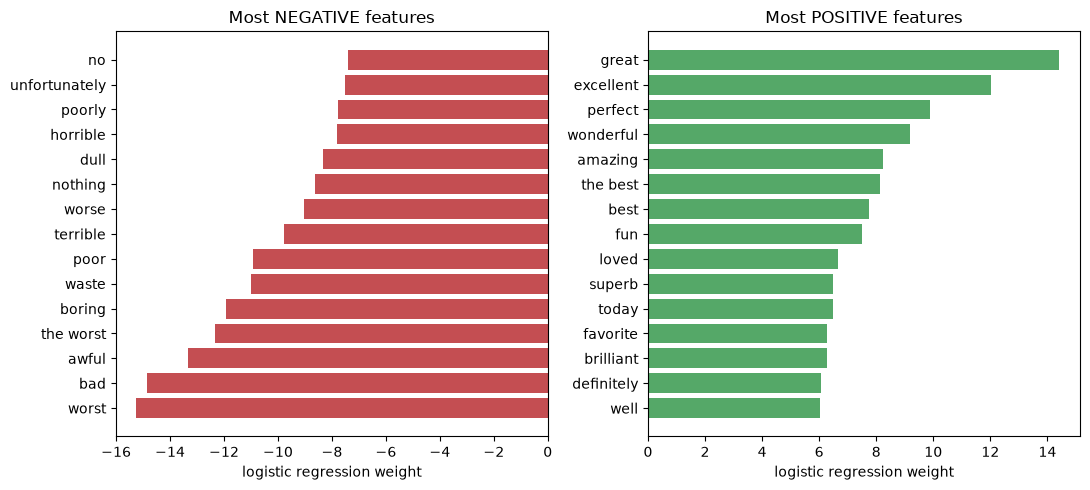

In [9]:
weights = lr_model.coef_[0]                         # one weight per feature
order = np.argsort(weights)                         # indices sorted from lowest to highest weight
top_neg = [(feature_names[i], weights[i]) for i in order[:15]]
top_pos = [(feature_names[i], weights[i]) for i in order[-15:]]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, items, color, title in [
    (axes[0], top_neg, "#C44E52", "Most NEGATIVE features"),
    (axes[1], top_pos, "#55A868", "Most POSITIVE features"),
]:
    names, values = zip(*items)
    ax.barh(names, values, color=color)
    ax.set_title(title)
    ax.set_xlabel("logistic regression weight")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "logreg_top_features.png", dpi=120)
plt.show()

The model found many of the same words we wrote by hand, **plus** domain-specific words and bigrams that no human would have listed. It learned them from 22,500 examples, in seconds to a few minutes.

### Explaining one single prediction
For a linear model, the contribution of each word is simply `tf-idf value × weight`. The sum of all contributions (plus the bias) decides the class.

In [10]:
def explain_prediction(review: str, top_k: int = 8) -> None:
    """Print the words that pushed the prediction most strongly in each direction."""
    vec = vectorizer.transform([review])               # 1 x n_features sparse vector
    contributions = vec.multiply(weights).toarray()[0]   # element-wise product
    nonzero = np.nonzero(contributions)[0]
    ranked = sorted(nonzero, key=lambda j: -abs(contributions[j]))[:top_k]

    prob_pos = lr_model.predict_proba(vec)[0, 1]
    print(f"\"{review}\"\n-> P(positive) = {prob_pos:.2f}")
    for j in ranked:
        print(f"   {feature_names[j]:<22} {contributions[j]:+.3f}")
    print()

explain_prediction("the actors are good , but the script is a boring mess .")
explain_prediction("not a great film , but never boring and often very funny .")

"the actors are good , but the script is a boring mess ."
-> P(positive) = 0.00
   boring                 -2.426
   mess                   -1.587
   script                 -1.109
   is boring              -0.602
   the script             -0.578
   good but               -0.526
   good                   +0.455
   actors                 -0.418

"not a great film , but never boring and often very funny ."
-> P(positive) = 0.76
   boring                 -2.226
   great                  +1.694
   boring and             -0.927
   great film             +0.649
   often                  +0.547
   very funny             +0.514
   not                    -0.402
   very                   +0.378



## 5. How much labelled data does ML need? (learning curve)

Heuristics need **zero** labelled examples. ML needs some. But how many? We train the same Logistic Regression pipeline on growing random subsets of the training data and measure test accuracy each time.

`make_pipeline` chains the vectorizer and the model, so the vectorizer is re-fitted on each subset. This is the realistic situation: if you only had 500 examples, your vocabulary would also only come from those 500.

In [11]:
sizes = [100, 250, 500, 1000, 2000, 4000, 8000, 16000, len(train)]
curve = []
for n in sizes:
    # Random subset of n training reviews; random_state makes it reproducible
    subset = train.sample(n=n, random_state=42) if n < len(train) else train
    pipe = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2 if n >= 1000 else 1, sublinear_tf=True),
        LogisticRegression(C=best_c, max_iter=2000),
    )
    pipe.fit(subset["text"], subset["label"])
    acc = (pipe.predict(X_test) == y_test).mean()
    curve.append({"n_train": n, "test_accuracy": round(float(acc), 4)})
    print(f"{n:>6,} training reviews -> test accuracy {acc:.4f}")

# Save for the comparison notebook
with open(RESULTS_DIR / "learning_curve_ml.json", "w", encoding="utf-8") as f:
    json.dump(curve, f, indent=2)

   100 training reviews -> test accuracy 0.7172
   250 training reviews -> test accuracy 0.7720
   500 training reviews -> test accuracy 0.8098
 1,000 training reviews -> test accuracy 0.8368
 2,000 training reviews -> test accuracy 0.8644
 4,000 training reviews -> test accuracy 0.8756
 8,000 training reviews -> test accuracy 0.8914
16,000 training reviews -> test accuracy 0.8990
22,500 training reviews -> test accuracy 0.9038


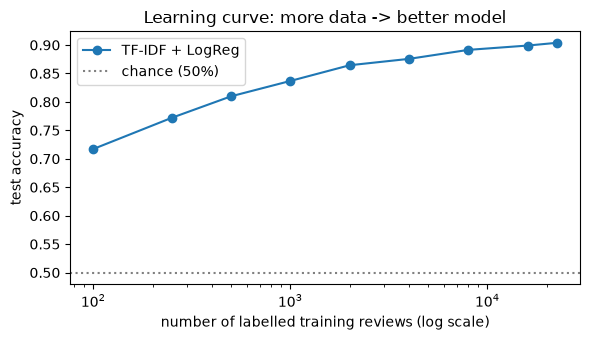

In [12]:
curve_df = pd.DataFrame(curve)
plt.figure(figsize=(6, 3.5))
plt.semilogx(curve_df["n_train"], curve_df["test_accuracy"], marker="o", label="TF-IDF + LogReg")
plt.axhline(0.5, color="gray", linestyle=":", label="chance (50%)")
plt.xlabel("number of labelled training reviews (log scale)")
plt.ylabel("test accuracy")
plt.title("Learning curve: more data -> better model")
plt.legend()
plt.tight_layout()
plt.show()

Compare the smallest training sizes with the heuristic scores from notebook 02: with very little data, ML has no big advantage over hand-written rules. Accuracy then grows roughly **linearly in log(n)**: every *doubling* of data gives a similar gain. That is a common pattern, and it means that each further percentage point gets more expensive.

## Summary: classic machine learning

| | |
|---|---|
| ✅ **Strengths** | Learns domain-specific words automatically · trains in seconds on a CPU · weights are readable (interpretable) · a strong, cheap baseline |
| ❌ **Weaknesses** | Needs labelled data · bag-of-words ignores word order beyond bigrams · cannot understand words it never saw in training · no world knowledge |
| 💡 **When to use** | Almost always as **the first real baseline**. In industry, TF-IDF + Logistic Regression is often good enough, and much cheaper than deep learning. |

**Next:** `04_deep_learning_approach.ipynb`, using a pre-trained transformer that already "knows" English before seeing our data.